# VisDrone EDA

Bu notebookta RT-DETR eğitimine başlamadan önce **VisDrone2019-DET** veri setine bakıyoruz. Amaç, modele vermeden önce veriyi tanımak: veri temiz mi, sınıflar dengeli mi, nesneler ne kadar küçük, train ile validation birbirine benziyor mu?

**Notebook akışı**

1. Dosya kontrolü
2. DataFrame oluşturma
3. Annotation kontrolleri (hatalı kayıt var mı?)
4. Sınıf isimleri ve veriyi ayırma
5. Sınıf dağılımı
6. Görüntü başına nesne sayısı
7. Bounding box boyutları
8. Çözünürlük ve resize etkisi (640x640)
9. Occlusion ve truncation

> Her bölümün sonunda **"Ne gördük?"** notu var, hızlıca bakmak isteyen sadece onları okuyabilir.

## 1. Dosya Kontrolü

Önce veri setinin yerinde olup olmadığına bakıyoruz: `images` ve `annotations` klasörleri var mı, görüntü sayısı ile annotation sayısı birbirini tutuyor mu?

In [84]:
from pathlib import Path

PROJECT_ROOT = Path.home() / "rtdetr_reproduction" / "RT-DETR"
DATASET_ROOT = PROJECT_ROOT / "datasets"

TRAIN_DIR = DATASET_ROOT / "VisDrone2019-DET-train"
VAL_DIR = DATASET_ROOT / "VisDrone2019-DET-val"

for name, folder in [("Train", TRAIN_DIR), ("Validation", VAL_DIR)]:
    images = folder / "images"
    annotations = folder / "annotations"

    print(f"\n{name}:")
    print("Images klasörü:", images.exists())
    print("Annotations klasörü:", annotations.exists())

    if images.exists():
        print("Görüntü sayısı:", len(list(images.glob("*.jpg"))))

    if annotations.exists():
        print("Annotation sayısı:", len(list(annotations.glob("*.txt"))))


Train:
Images klasörü: True
Annotations klasörü: True
Görüntü sayısı: 6471
Annotation sayısı: 6471

Validation:
Images klasörü: True
Annotations klasörü: True
Görüntü sayısı: 548
Annotation sayısı: 548


**Ne gördük?** Train'de 6471, validation'da 548 görüntü var ve her görüntünün bir annotation dosyası var. Sayılar eşleşiyor.

## 2. DataFrame Oluşturma

Her görüntünün bir `.txt` annotation dosyası var ve dosyadaki her satır bir nesneyi anlatıyor. Satırdaki 8 sütunun anlamı:

| Sütun | Anlamı |
|---|---|
| `bbox_left`, `bbox_top` | Kutunun sol üst köşesi |
| `bbox_width`, `bbox_height` | Kutunun genişliği ve yüksekliği |
| `score` | 1 = geçerli nesne, 0 = değerlendirmede dikkate alınmaz |
| `category` | Sınıf numarası (0-11) |
| `truncation` | 0 = tam görünür, 1 = görüntü kenarında kesilmiş |
| `occlusion` | 0 = kapalı değil, 1 = kısmen kapalı, 2 = çok kapalı |

Tüm dosyaları okuyup tek bir DataFrame'de birleştiriyoruz. `image_id` sütunu da hangi nesnenin hangi görüntüye ait olduğunu tutuyor.

In [85]:
import pandas as pd

COLUMNS = [
    "bbox_left",
    "bbox_top",
    "bbox_width",
    "bbox_height",
    "score",
    "category",
    "truncation",
    "occlusion"
]


def load_annotations(annotation_dir):
    dataframes = []

    for file_path in sorted(annotation_dir.glob("*.txt")):
        df = pd.read_csv(
            file_path,
            header=None,
            names=COLUMNS,
            index_col=False
        )

        df["image_id"] = file_path.stem
        dataframes.append(df)

    return pd.concat(dataframes, ignore_index=True)


train_df = load_annotations(TRAIN_DIR / "annotations")
val_df = load_annotations(VAL_DIR / "annotations")

## 3. Annotation Kontrolleri

Burada verinin temiz olup olmadığına bakıyoruz. Şunları kontrol ediyoruz:

- Category 0-11 aralığında mı?
- Kutu genişliği ve yüksekliği 0'dan büyük mü?
- Kutu koordinatları negatif mi?
- Truncation ve occlusion değerleri beklenen aralıkta mı?
- Eksik (boş) değer var mı?

In [86]:
def check_annotations(df, split_name):

    checks = {
        "Geçersiz category":
            ~df["category"].isin(range(12)),

        "Geçersiz bbox_width":
            df["bbox_width"] <= 0,

        "Geçersiz bbox_height":
            df["bbox_height"] <= 0,

        "Negatif bbox_left":
            df["bbox_left"] < 0,

        "Negatif bbox_top":
            df["bbox_top"] < 0,

        "Geçersiz truncation":
            ~df["truncation"].isin([0, 1]),

        "Geçersiz occlusion":
            ~df["occlusion"].isin([0, 1, 2]),

        "Eksik değer":
            df.isna().any(axis=1)
    }

    print(f"\n{split_name} - Annotation Kontrolleri")
    print("-" * 45)

    for check_name, condition in checks.items():
        print(f"{check_name}: {condition.sum()}")


check_annotations(train_df, "TRAIN")
check_annotations(val_df, "VALIDATION")


TRAIN - Annotation Kontrolleri
---------------------------------------------
Geçersiz category: 0
Geçersiz bbox_width: 0
Geçersiz bbox_height: 3
Negatif bbox_left: 0
Negatif bbox_top: 0
Geçersiz truncation: 0
Geçersiz occlusion: 0
Eksik değer: 0

VALIDATION - Annotation Kontrolleri
---------------------------------------------
Geçersiz category: 0
Geçersiz bbox_width: 0
Geçersiz bbox_height: 0
Negatif bbox_left: 0
Negatif bbox_top: 0
Geçersiz truncation: 0
Geçersiz occlusion: 0
Eksik değer: 0


**Ne gördük?** Validation tamamen temiz. Train'de ise sadece **3 kutunun yüksekliği 0** çıkmış. Aşağıda bu kayıtlara bakıyoruz.

In [87]:
invalid_height = train_df[
    train_df["bbox_height"] <= 0
]

display(invalid_height)

,bbox_left,bbox_top,bbox_width,bbox_height,score,category,truncation,occlusion,image_id
66237,1008,374,3,0,0,0,0,0,0000293_03401_d_0000939
277416,611,158,4,0,1,4,0,0,9999985_00000_d_0000020
342695,545,414,10,0,0,0,0,0,9999999_00590_d_0000267


3 kayıttan 2'si `ignored_regions` (category 0), 1'i `car`. Sayıca çok az ama yüksekliği 0 olan bir kutu eğitimde sorun çıkarabilir. O yüzden ileride sadece geçerli kutuları alırken bunları eleyeceğiz.

### Görüntü boyutlarını okuma

Kutuların görüntü dışına taşıp taşmadığını kontrol edebilmek için her görüntünün genişlik ve yüksekliğini okuyoruz.

In [88]:
from PIL import Image

def get_image_sizes(images_dir):
    image_sizes = []

    for image_path in sorted(images_dir.glob("*.jpg")):
        with Image.open(image_path) as img:
            width, height = img.size

        image_sizes.append({
            "image_id": image_path.stem,
            "image_width": width,
            "image_height": height
        })

    return pd.DataFrame(image_sizes)


train_image_sizes = get_image_sizes(TRAIN_DIR / "images")
val_image_sizes = get_image_sizes(VAL_DIR / "images")

display(train_image_sizes.head())

,image_id,image_width,image_height
0,0000002_00005_d_0000014,960,540
1,0000002_00448_d_0000015,960,540
2,0000003_00231_d_0000016,960,540
3,0000007_04999_d_0000036,1360,765
4,0000007_05499_d_0000037,1360,765


Okuduğumuz görüntü boyutlarını `image_id` üzerinden annotation tablosuna ekliyoruz. `validate="many_to_one"` sayesinde birleştirmenin doğru yapıldığından emin oluyoruz (bir görüntüye birçok nesne düşebilir ama tersi olamaz).

In [89]:
train_df = train_df.merge(
    train_image_sizes,
    on="image_id",
    how="left",
    validate="many_to_one"
)

val_df = val_df.merge(
    val_image_sizes,
    on="image_id",
    how="left",
    validate="many_to_one"
)

### Sınır dışı kutu kontrolü

Kutunun sağ alt köşesi (`left + width`, `top + height`) görüntü boyutunu aşıyor mu? Ya da sol üst köşe negatif mi? Böyle kutular varsa düzeltmemiz gerekir.

In [90]:
def check_bbox_boundaries(df, split_name):

    x_max = df["bbox_left"] + df["bbox_width"]
    y_max = df["bbox_top"] + df["bbox_height"]

    out_of_bounds = df[
        (x_max > df["image_width"]) |
        (y_max > df["image_height"]) |
        (df["bbox_left"] < 0) |
        (df["bbox_top"] < 0)
    ].copy()

    print(f"{split_name} sınır dışı bbox sayısı:", len(out_of_bounds))

    return out_of_bounds


train_out_of_bounds = check_bbox_boundaries(train_df, "TRAIN")
val_out_of_bounds = check_bbox_boundaries(val_df, "VALIDATION")

if train_out_of_bounds.shape[0] > 0:
    display(train_out_of_bounds.head(10))

if val_out_of_bounds.shape[0] > 0:
    display(val_out_of_bounds.head(10))

TRAIN sınır dışı bbox sayısı: 0
VALIDATION sınır dışı bbox sayısı: 0


Birleştirme sırasında boyut bilgisi gelmeyen (eşleşmeyen) görüntü kalmış mı, ona da bakıyoruz.

In [91]:
print("Train eşleşmeyen görüntü:",
      train_df["image_width"].isna().sum())

print("Validation eşleşmeyen görüntü:",
      val_df["image_width"].isna().sum())

Train eşleşmeyen görüntü: 0
Validation eşleşmeyen görüntü: 0


**Ne gördük?** Sınır dışına taşan kutu yok, eşleşmeyen görüntü de yok. Birleştirme sorunsuz.

### Score ve category tutarlılığı

Veri setinin kuralı şu:

- Category **0** (ignored regions) ve **11** (others) için `score = 0`
- Category **1-10** (gerçek nesneler) için `score = 1`

Bu kurala uymayan kayıt var mı diye bakıyoruz.

In [92]:
def check_score_category_consistency(df, split_name):

    outliers_0 = df[
        (df["category"] == 0) &
        (df["score"] != 0)
    ]

    outliers_11 = df[
        (df["category"] == 11) &
        (df["score"] != 0)
    ]

    outliers_objects = df[
        (df["category"].between(1, 10)) &
        (df["score"] != 1)
    ]

    print(f"\n{split_name} - Score & Category Kontrolü")
    print("-" * 45)

    print("Category 0 hataları:", len(outliers_0))
    print("Category 11 hataları:", len(outliers_11))
    print("Category 1-10 hataları:", len(outliers_objects))

    return {
        "category_0": outliers_0,
        "category_11": outliers_11,
        "objects": outliers_objects
    }

In [93]:
train_outliers = check_score_category_consistency(train_df, "TRAIN")
val_outliers = check_score_category_consistency(val_df, "VALIDATION")


TRAIN - Score & Category Kontrolü
---------------------------------------------
Category 0 hataları: 0
Category 11 hataları: 0
Category 1-10 hataları: 0

VALIDATION - Score & Category Kontrolü
---------------------------------------------
Category 0 hataları: 0
Category 11 hataları: 0
Category 1-10 hataları: 0


**Ne gördük?** Hiç hatalı kayıt yok, kurallar her iki sette de tutuyor.

## 4. Sınıf İsimleri ve Veriyi Ayırma

Category numaralarını okunabilir isimlerle eşleştirip DataFrame'e `class_name` sütunu olarak ekliyoruz.

In [94]:
CLASS_NAMES = {
    0: "ignored_regions",
    1: "pedestrian",
    2: "people",
    3: "bicycle",
    4: "car",
    5: "van",
    6: "truck",
    7: "tricycle",
    8: "awning-tricycle",
    9: "bus",
    10: "motor",
    11: "others"
}

In [95]:
train_df["class_name"] = train_df["category"].map(CLASS_NAMES)
val_df["class_name"] = val_df["category"].map(CLASS_NAMES)

In [96]:
display(train_df[["category", "class_name"]].head(10))

display(val_df[["category", "class_name"]].head(10))

,category,class_name
0,0,ignored_regions
1,0,ignored_regions
2,0,ignored_regions
3,0,ignored_regions
4,4,car
5,4,car
6,4,car
7,4,car
8,4,car
9,4,car


,category,class_name
0,4,car
1,4,car
2,4,car
3,10,motor
4,2,people
5,10,motor
6,1,pedestrian
7,1,pedestrian
8,8,awning-tricycle
9,2,people


Şimdi kayıtları iki gruba ayırıyoruz:

- **`objects`**: Category 1-10, `score = 1` ve kutu boyutu geçerli olanlar. Analizi ve eğitimi bunlarla yapacağız.
- **`special`**: Category 0 (ignored regions) ve 11 (others). Bunlar gerçek nesne sayılmıyor, ayrı tutuyoruz.

In [97]:
def get_valid_objects(df):
    return df[
        (df["category"].between(1, 10)) &
        (df["score"] == 1) &
        (df["bbox_width"] > 0) &
        (df["bbox_height"] > 0)
    ].copy()


train_objects = get_valid_objects(train_df)
val_objects = get_valid_objects(val_df)

In [98]:
def get_special_objects(df):
    return df[
        df["category"].isin([0, 11])
    ].copy()


train_special = get_special_objects(train_df)
val_special = get_special_objects(val_df)

Küçük bir doğruluk testi: toplam kayıt sayısı, `objects` ve `special` toplamına eşit olmalı.

**Ne gördük?** Validation'da fark 0. Train'de dışarıda 1 kayıt kalıyor, bu da yukarıda bulduğumuz yüksekliği 0 olan `car` kutusu. Yani sonuç beklediğimiz gibi.

In [99]:
print(
    "Train dışarıda kalan kayıt:",
    len(train_df) - len(train_objects) - len(train_special)
)

print(
    "Validation dışarıda kalan kayıt:",
    len(val_df) - len(val_objects) - len(val_special)
)

Train dışarıda kalan kayıt: 1
Validation dışarıda kalan kayıt: 0


## 5. Sınıf Dağılımı

Hangi sınıftan kaç nesne var? Dağılım çok dengesizse model az örneği olan sınıfları öğrenmekte zorlanabilir. Yüzdeler, ignored ve others hariç 10 gerçek sınıf üzerinden hesaplandı.

In [100]:
def get_class_distribution(df):
    distribution = (
        df["class_name"]
        .value_counts()
        .rename_axis("class_name")
        .reset_index(name="count")
    )

    distribution["percentage"] = (
        distribution["count"] / distribution["count"].sum() * 100
    )

    return distribution


train_distribution = get_class_distribution(train_objects)
val_distribution = get_class_distribution(val_objects)

print("TRAIN CLASS DISTRIBUTION")
display(train_distribution)

print("VALIDATION CLASS DISTRIBUTION")
display(val_distribution)

TRAIN CLASS DISTRIBUTION


,class_name,count,percentage
0,car,144866,42.209881
1,pedestrian,79337,23.116572
2,motor,29647,8.638303
3,people,27059,7.884232
4,van,24956,7.271477
5,truck,12875,3.751413
6,bicycle,10480,3.053577
7,bus,5926,1.726670
8,tricycle,4812,1.402082
9,awning-tricycle,3246,0.945793


VALIDATION CLASS DISTRIBUTION


,class_name,count,percentage
0,car,14064,36.285766
1,pedestrian,8844,22.817926
2,people,5125,13.222735
3,motor,4886,12.606104
4,van,1975,5.095591
5,bicycle,1287,3.320519
6,tricycle,1045,2.696148
7,truck,750,1.935034
8,awning-tricycle,532,1.372584
9,bus,251,0.647592


Train ve validation yüzdelerini yan yana koyup aradaki farka bakıyoruz.

In [101]:
comparison = train_distribution.merge(
    val_distribution,
    on="class_name",
    suffixes=("_train", "_val")
)

comparison["percentage_diff"] = (
    comparison["percentage_train"] -
    comparison["percentage_val"]
)

comparison = comparison.sort_values(
    "percentage_train",
    ascending=False
)

display(comparison)

,class_name,count_train,percentage_train,count_val,percentage_val,percentage_diff
0,car,144866,42.209881,14064,36.285766,5.924115
1,pedestrian,79337,23.116572,8844,22.817926,0.298646
2,motor,29647,8.638303,4886,12.606104,-3.967802
3,people,27059,7.884232,5125,13.222735,-5.338503
4,van,24956,7.271477,1975,5.095591,2.175886
5,truck,12875,3.751413,750,1.935034,1.816379
6,bicycle,10480,3.053577,1287,3.320519,-0.266942
7,bus,5926,1.726670,251,0.647592,1.079078
8,tricycle,4812,1.402082,1045,2.696148,-1.294066
9,awning-tricycle,3246,0.945793,532,1.372584,-0.426791


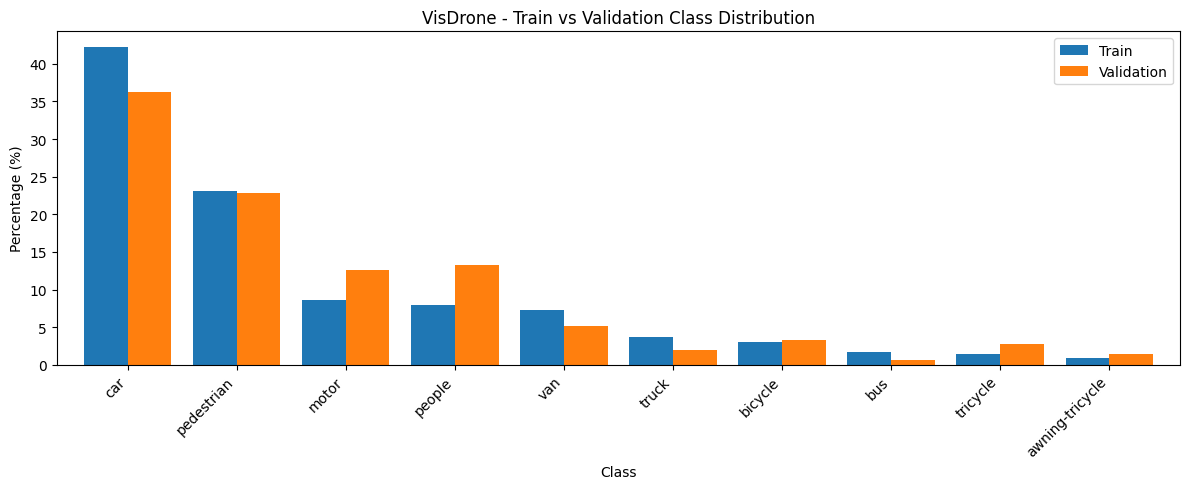

In [102]:
import matplotlib.pyplot as plt

ax = comparison.plot(
    x="class_name",
    y=["percentage_train", "percentage_val"],
    kind="bar",
    figsize=(12, 5),
    width=0.8
)

plt.title("VisDrone - Train vs Validation Class Distribution")
plt.xlabel("Class")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(["Train", "Validation"])
plt.tight_layout()
plt.show()

**Ne gördük?**

- `car` açık ara en çok olan sınıf (train'de yaklaşık %42), ardından `pedestrian` geliyor (%23).
- `awning-tricycle`, `tricycle` ve `bus` en az olanlar (%1-2). Yani sınıflar dengesiz.
- Train ve validation'ın genel sıralaması benzer ama oranlar tam aynı değil. `car` train'de daha fazla, `people` ve `motor` ise validation'da daha fazla.

## 6. Görüntü Başına Nesne Sayısı

Bir görüntüde ortalama kaç nesne var? Çok kalabalık görüntüler hem eğitimi zorlaştırır hem de modelin tek seferde üretebildiği tahmin sayısıyla (RT-DETR'de varsayılan 300) ilgili olduğu için önemli.

In [103]:
def get_objects_per_image(objects_df, all_images_df):

    counts = (
        objects_df.groupby("image_id")
        .size()
        .rename("object_count")
    )

    result = all_images_df[["image_id"]].drop_duplicates().merge(
        counts,
        on="image_id",
        how="left"
    )

    result["object_count"] = (
        result["object_count"].fillna(0).astype(int)
    )

    return result


train_objects_per_image = get_objects_per_image(
    train_objects, train_image_sizes
)

val_objects_per_image = get_objects_per_image(
    val_objects, val_image_sizes
)

Görüntü başına nesne sayısının istatistiklerini çıkarıyoruz.

In [104]:
import pandas as pd

def get_object_statistics(df):
    counts = df["object_count"]

    return {
        "Total Images": len(df),
        "Total Objects": counts.sum(),
        "Images With Objects": (counts > 0).sum(),
        "Images Without Objects": (counts == 0).sum(),
        "Mean": counts.mean(),
        "Median": counts.median(),
        "Std": counts.std(),
        "Min": counts.min(),
        "25%": counts.quantile(0.25),
        "50%": counts.quantile(0.50),
        "75%": counts.quantile(0.75),
        "90%": counts.quantile(0.90),
        "95%": counts.quantile(0.95),
        "99%": counts.quantile(0.99),
        "Max": counts.max()
    }


# Train ve Validation istatistiklerini hesapla
train_stats = get_object_statistics(train_objects_per_image)
val_stats = get_object_statistics(val_objects_per_image)

# Yan yana karşılaştırma tablosu oluştur
statistics_df = pd.DataFrame({
    "Train": train_stats,
    "Validation": val_stats
})

display(statistics_df)

,Train,Validation
Total Images,6471.000000,548.000000
Total Objects,343204.000000,38759.000000
Images With Objects,6471.000000,548.000000
Images Without Objects,0.000000,0.000000
Mean,53.037243,70.728102
Median,42.000000,65.000000
Std,43.841999,45.995439
Min,1.000000,1.000000
25%,24.000000,39.750000
50%,42.000000,65.000000


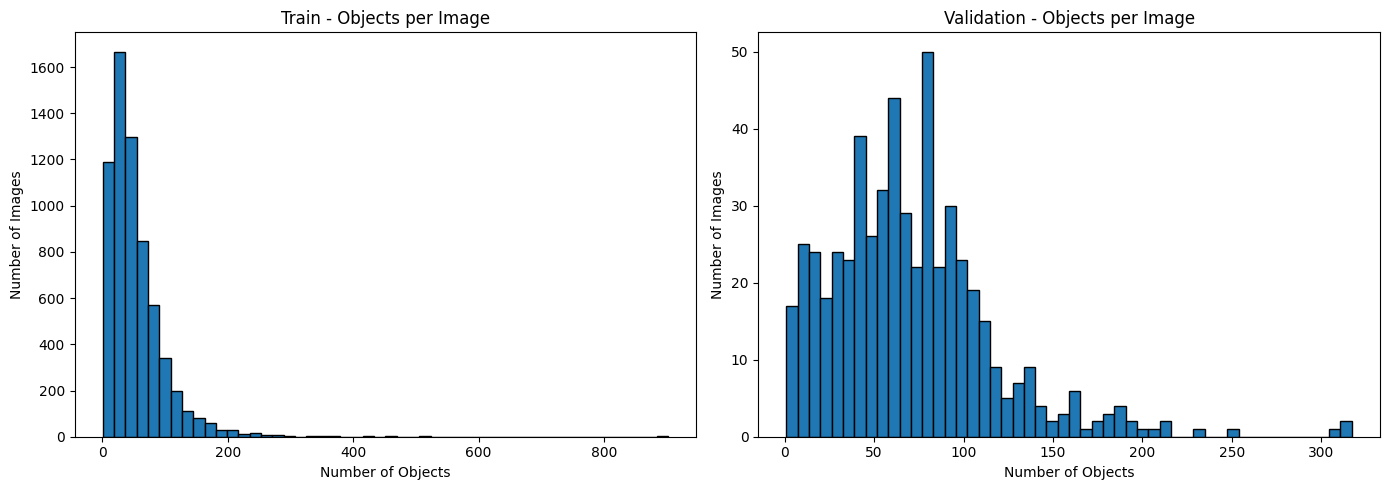

In [105]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    train_objects_per_image["object_count"],
    bins=50,
    edgecolor="black"
)
axes[0].set_title("Train - Objects per Image")
axes[0].set_xlabel("Number of Objects")
axes[0].set_ylabel("Number of Images")

axes[1].hist(
    val_objects_per_image["object_count"],
    bins=50,
    edgecolor="black"
)
axes[1].set_title("Validation - Objects per Image")
axes[1].set_xlabel("Number of Objects")
axes[1].set_ylabel("Number of Images")

plt.tight_layout()
plt.show()

**Ne gördük?**

- Train'de görüntü başına ortalama yaklaşık 53 nesne var (median 42). Validation'da ortalama yaklaşık 71 (median 65). Yani **validation görüntüleri daha kalabalık**.
- Her görüntüde en az 1 nesne var, nesnesiz görüntü yok.
- Dağılım sağa çarpık: çoğu görüntüde az nesne var, birkaç görüntüde çok fazla (train'de en fazla 902).

### Çok kalabalık görüntüler

Eşik olarak 300 seçtik ve bundan fazla nesne içeren görüntüleri sayıyoruz.

In [106]:
def check_dense_images(df, threshold=300):
    dense_images = df[df["object_count"] > threshold]

    print(f"{threshold}'den fazla nesne içeren görüntü:", len(dense_images))
    print(f"Toplam görüntülere oranı: %{len(dense_images) / len(df) * 100:.2f}")

    return dense_images.sort_values("object_count", ascending=False)


print("TRAIN")
train_dense = check_dense_images(train_objects_per_image)

print("\nVALIDATION")
val_dense = check_dense_images(val_objects_per_image)

display(train_dense)
display(val_dense.head(10))

TRAIN
300'den fazla nesne içeren görüntü: 12
Toplam görüntülere oranı: %0.19

VALIDATION
300'den fazla nesne içeren görüntü: 3
Toplam görüntülere oranı: %0.55


,image_id,object_count
51,0000059_01886_d_0000114,902
221,0000137_02220_d_0000163,512
264,0000143_01681_d_0000056,462
196,0000126_11844_d_0000130,431
254,0000142_04458_d_0000045,370
1979,9999943_00000_d_0000049,351
209,0000135_01327_d_0000151,348
220,0000137_01824_d_0000162,346
261,0000143_00881_d_0000052,342
253,0000142_04058_d_0000043,306


,image_id,object_count
374,0000295_02400_d_0000033,317
372,0000295_02000_d_0000031,311
371,0000295_01800_d_0000030,306


**Ne gördük?** Train'de 12 (%0.19), validation'da 3 (%0.55) görüntü 300'den fazla nesne içeriyor. Çok az ama uç örnekler. En kalabalık olan `0000059_01886_d_0000114` (902 nesne), aşağıda ona bakacağız.

### En kalabalık görüntüye bakalım

Önce görüntünün kendisini çizdiriyoruz.

Image size: (960, 540)


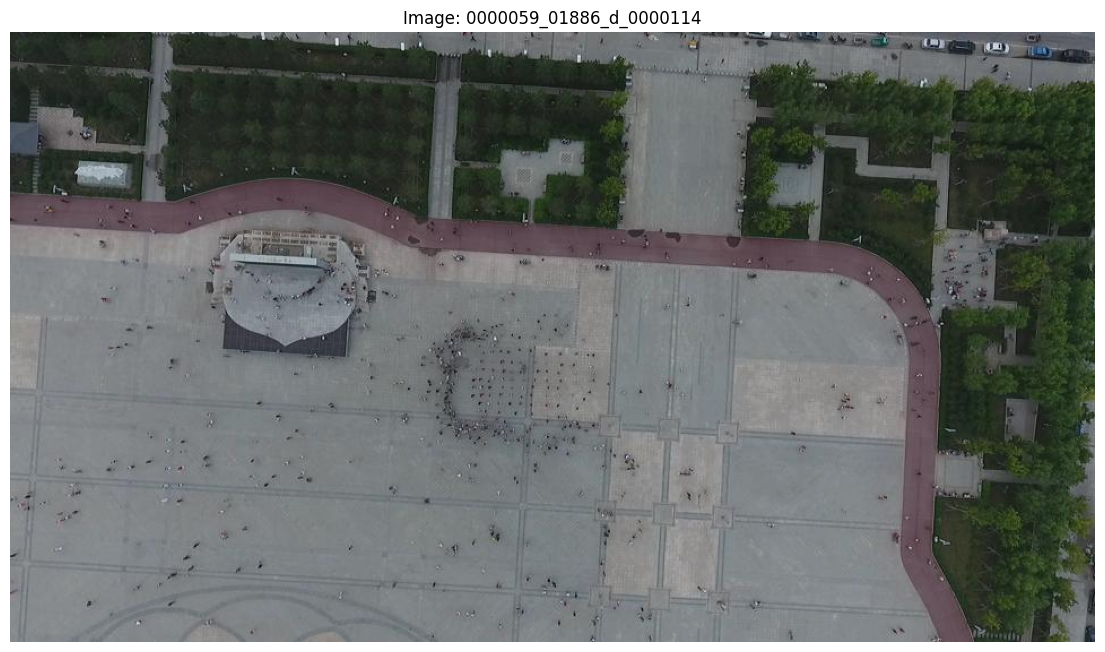

In [107]:
from PIL import Image
import matplotlib.pyplot as plt

image_id = "0000059_01886_d_0000114"

image_path = TRAIN_DIR / "images" / f"{image_id}.jpg"

image = Image.open(image_path)

print("Image size:", image.size)

plt.figure(figsize=(14, 10))
plt.imshow(image)
plt.axis("off")
plt.title(f"Image: {image_id}")
plt.show()

Şimdi aynı görüntünün üzerine annotation kutularını çiziyoruz.

Object count: 902


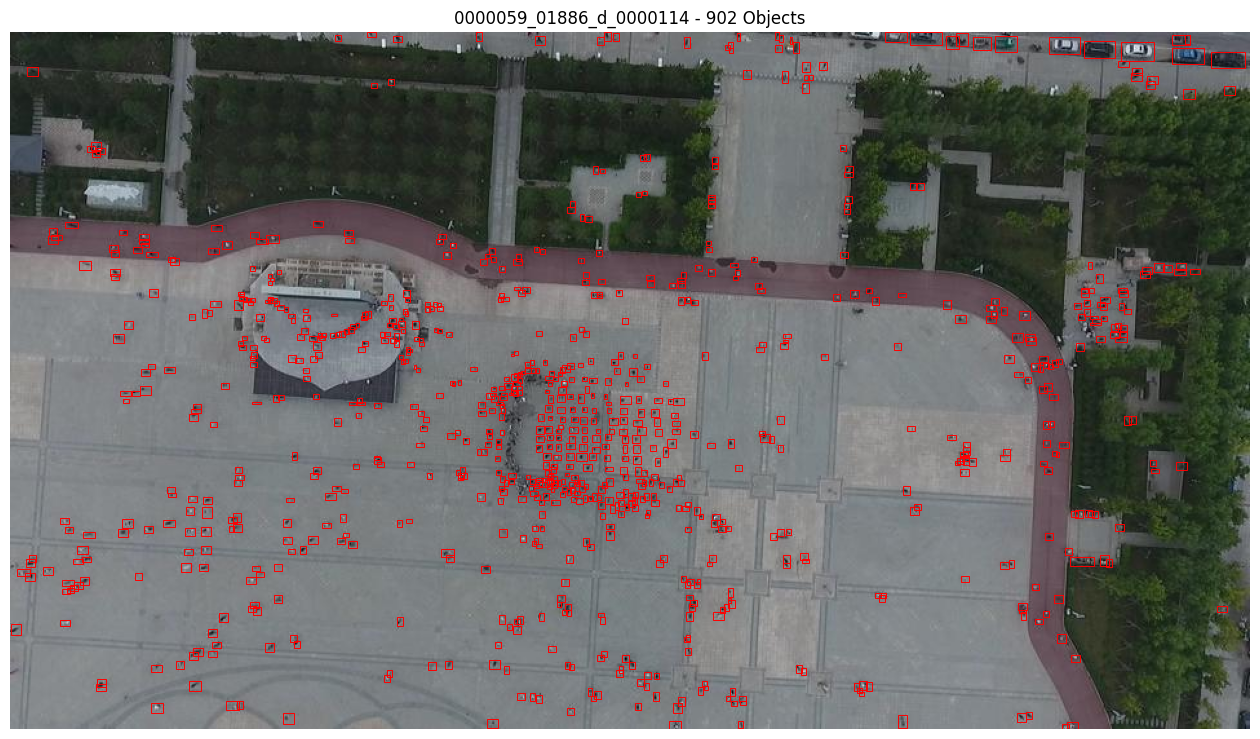

In [108]:
import matplotlib.patches as patches

# Bu görüntüye ait geçerli annotation'ları seç
image_objects = train_objects[
    train_objects["image_id"] == image_id
]

print("Object count:", len(image_objects))

fig, ax = plt.subplots(figsize=(16, 12))

ax.imshow(image)

for _, obj in image_objects.iterrows():

    x = obj["bbox_left"]
    y = obj["bbox_top"]
    w = obj["bbox_width"]
    h = obj["bbox_height"]

    rect = patches.Rectangle(
        (x, y),
        w,
        h,
        linewidth=0.7,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)

ax.set_title(f"{image_id} - {len(image_objects)} Objects")
ax.axis("off")

plt.show()

Bu görüntüdeki nesnelerin sınıf dağılımı:

In [109]:
class_counts = (
    image_objects["class_name"]
    .value_counts()
    .rename_axis("class_name")
    .reset_index(name="count")
)

display(class_counts)

,class_name,count
0,pedestrian,842
1,people,46
2,car,8
3,tricycle,3
4,motor,2
5,awning-tricycle,1


Bu görüntüdeki `pedestrian` kutularının boyutları (piksel cinsinden):

In [110]:
pedestrians = image_objects[
    image_objects["class_name"] == "pedestrian"
].copy()

pedestrians["bbox_area"] = (
    pedestrians["bbox_width"] *
    pedestrians["bbox_height"]
)

display(
    pedestrians[
        ["bbox_width", "bbox_height", "bbox_area"]
    ].describe()
)

,bbox_width,bbox_height,bbox_area
count,842.000000,842.000000,842.000000
mean,5.243468,4.678147,25.356295
std,1.562449,1.208264,12.219802
min,2.000000,2.000000,6.000000
25%,4.000000,4.000000,16.000000
50%,5.000000,5.000000,24.000000
75%,6.000000,5.000000,30.000000
max,10.000000,10.000000,72.000000


**Ne gördük?** 902 nesnenin 842'si `pedestrian` ve hepsi çok küçük (median alan 24 piksel, yani yaklaşık 5x5). Bu tarz görüntüler hem kalabalık hem de minik nesnelerle dolu, modelin en çok zorlanacağı örnekler.

## 7. Bounding Box Boyutları

Bu bölümde nesnelerin ne kadar büyük ya da küçük olduğuna bakıyoruz. Önce orijinal piksel boyutlarıyla, sınıf bazında genişlik, yükseklik ve alan istatistikleri.

In [111]:
def get_bbox_statistics_by_class(df):

    data = df.copy()

    # Bounding box alanını hesapla
    data["bbox_area"] = (
        data["bbox_width"] * data["bbox_height"]
    )

    # Sınıflara göre istatistikleri hesapla
    stats = data.groupby("class_name").agg(
        object_count=("bbox_width", "count"),

        width_min=("bbox_width", "min"),
        width_max=("bbox_width", "max"),
        width_mean=("bbox_width", "mean"),
        width_median=("bbox_width", "median"),

        height_min=("bbox_height", "min"),
        height_max=("bbox_height", "max"),
        height_mean=("bbox_height", "mean"),
        height_median=("bbox_height", "median"),

        area_min=("bbox_area", "min"),
        area_max=("bbox_area", "max"),
        area_mean=("bbox_area", "mean"),
        area_median=("bbox_area", "median")
    )

    return stats.round(2)


train_bbox_stats = get_bbox_statistics_by_class(train_objects)
val_bbox_stats = get_bbox_statistics_by_class(val_objects)

print("TRAIN - BBOX STATISTICS BY CLASS")
display(train_bbox_stats)

print("VALIDATION - BBOX STATISTICS BY CLASS")
display(val_bbox_stats)

TRAIN - BBOX STATISTICS BY CLASS


,object_count,width_min,width_max,width_mean,width_median,height_min,height_max,height_mean,height_median,area_min,area_max,area_mean,area_median
class_name,,,,,,,,,,,,,
awning-tricycle,3246,3,338,45.28,36.0,4,350,45.05,36.0,16,66048,2905.23,1320.0
bicycle,10480,3,332,29.46,24.0,1,271,31.21,26.0,9,60756,1221.88,612.0
bus,5926,3,690,67.07,49.0,4,663,65.63,48.0,12,324300,6971.60,2378.0
car,144866,2,717,51.26,38.0,1,790,40.61,29.0,3,328640,3289.26,1104.0
motor,29647,2,260,26.65,22.0,1,280,27.74,23.0,8,64680,993.92,512.0
pedestrian,79337,2,273,16.22,13.0,2,321,30.73,25.0,6,43656,712.29,315.0
people,27059,2,215,16.43,13.0,1,338,24.71,20.0,3,72670,591.58,273.0
tricycle,4812,3,411,45.10,36.0,3,347,40.40,33.0,9,100170,2547.02,1188.0
truck,12875,3,983,67.73,49.0,3,704,60.72,43.0,9,315202,6473.57,2145.0


VALIDATION - BBOX STATISTICS BY CLASS


,object_count,width_min,width_max,width_mean,width_median,height_min,height_max,height_mean,height_median,area_min,area_max,area_mean,area_median
class_name,,,,,,,,,,,,,
awning-tricycle,532,4,331,33.67,28.0,5,197,34.37,30.0,20,65207,1556.30,858.0
bicycle,1287,3,176,23.17,20.0,3,242,24.82,22.0,15,25894,708.03,432.0
bus,251,4,519,51.13,34.0,5,276,51.14,37.0,24,92382,4646.20,1242.0
car,14064,2,577,47.74,38.0,2,616,35.18,27.0,4,355432,2495.86,1056.0
motor,4886,2,249,22.42,19.0,2,236,23.91,21.0,6,58764,684.58,400.0
pedestrian,8844,2,157,13.08,11.0,3,385,30.75,28.0,6,58135,537.89,295.0
people,5125,2,115,14.74,13.0,3,175,24.10,22.0,8,20125,458.00,280.0
tricycle,1045,2,189,35.99,30.0,4,146,31.16,26.0,8,25704,1459.07,805.0
truck,750,5,580,57.69,43.0,5,547,50.46,34.0,25,317260,4950.17,1491.0


**Ne gördük?** `pedestrian` ve `people` en küçük sınıflar (median genişlik yaklaşık 13 piksel). `bus`, `truck` ve `car` en büyükler. Validation'daki kutular çoğu sınıfta train'e göre biraz daha küçük.

### Small / Medium / Large

COCO'daki gibi alana göre üç gruba ayırıyoruz:

- **Small**: alan < 32² (1024 piksel²)
- **Medium**: 32² ile 96² arası
- **Large**: alan > 96²

In [112]:
import pandas as pd

def get_object_size_distribution(df):

    data = df.copy()

    # Bounding box alanı
    data["bbox_area"] = (
        data["bbox_width"] * data["bbox_height"]
    )

    # Alanlarına göre boyut kategorileri
    data["size_category"] = pd.cut(
        data["bbox_area"],
        bins=[0, 32**2, 96**2, float("inf")],
        labels=["Small", "Medium", "Large"],
        right=False
    )

    # Her sınıfta kaç Small / Medium / Large var?
    counts = pd.crosstab(
        data["class_name"],
        data["size_category"]
    )

    # Sınıf içindeki yüzdeleri hesapla
    percentages = (
        counts.div(counts.sum(axis=1), axis=0) * 100
    )

    return counts, percentages.round(2)


train_size_counts, train_size_percentages = (
    get_object_size_distribution(train_objects)
)

val_size_counts, val_size_percentages = (
    get_object_size_distribution(val_objects)
)

print("TRAIN - SIZE COUNTS")
display(train_size_counts)

print("TRAIN - SIZE PERCENTAGES")
display(train_size_percentages)

print("VALIDATION - SIZE COUNTS")
display(val_size_counts)

print("VALIDATION - SIZE PERCENTAGES")
display(val_size_percentages)

TRAIN - SIZE COUNTS


size_category,Small,Medium,Large
class_name,,,
awning-tricycle,1365,1695,186
bicycle,7100,3253,127
bus,1657,3269,1000
car,69801,63125,11940
motor,21964,7416,267
pedestrian,65233,13798,306
people,23505,3455,99
tricycle,2178,2424,210
truck,3984,6724,2167


TRAIN - SIZE PERCENTAGES


size_category,Small,Medium,Large
class_name,,,
awning-tricycle,42.05,52.22,5.73
bicycle,67.75,31.04,1.21
bus,27.96,55.16,16.87
car,48.18,43.57,8.24
motor,74.09,25.01,0.90
pedestrian,82.22,17.39,0.39
people,86.87,12.77,0.37
tricycle,45.26,50.37,4.36
truck,30.94,52.23,16.83


VALIDATION - SIZE COUNTS


size_category,Small,Medium,Large
class_name,,,
awning-tricycle,305,222,5
bicycle,1053,231,3
bus,116,103,32
car,6902,6383,779
motor,3977,902,7
pedestrian,7746,1075,23
people,4631,489,5
tricycle,620,413,12
truck,289,374,87


VALIDATION - SIZE PERCENTAGES


size_category,Small,Medium,Large
class_name,,,
awning-tricycle,57.33,41.73,0.94
bicycle,81.82,17.95,0.23
bus,46.22,41.04,12.75
car,49.08,45.39,5.54
motor,81.40,18.46,0.14
pedestrian,87.58,12.16,0.26
people,90.36,9.54,0.10
tricycle,59.33,39.52,1.15
truck,38.53,49.87,11.60


**Ne gördük?** `pedestrian` ve `people` nesnelerinin %82-90'ı Small. `motor` ve `bicycle` da ağırlıklı olarak Small. Genel olarak veri seti **küçük nesne ağırlıklı**, Large grup sadece `bus`, `truck` ve `van` gibi büyük araçlarda anlamlı bir paya sahip.

### Daha ayrıntılı boyut grupları

Small grubu çok geniş kaldığı için küçük nesneleri daha ince gruplara ayırıyoruz (alan, piksel² cinsinden):

| Grup | Alan |
|---|---|
| Extremely Tiny | < 16 |
| Tiny | 16 - 64 |
| Very Small | 64 - 256 |
| Small | 256 - 1024 |
| Medium | 1024 - 9216 |
| Large | > 9216 |

In [113]:
def get_detailed_size_distribution(df):

    data = df.copy()

    data["bbox_area"] = (
        data["bbox_width"] * data["bbox_height"]
    )

    bins = [0, 16, 64, 256, 1024, 9216, float("inf")]

    labels = [
        "Extremely Tiny",
        "Tiny",
        "Very Small",
        "Small",
        "Medium",
        "Large"
    ]

    data["size_group"] = pd.cut(
        data["bbox_area"],
        bins=bins,
        labels=labels,
        right=False
    )

    counts = pd.crosstab(
        data["class_name"],
        data["size_group"]
    )

    percentages = (
        counts.div(counts.sum(axis=1), axis=0) * 100
    ).round(2)

    return counts, percentages


train_detailed_counts, train_detailed_pct = (
    get_detailed_size_distribution(train_objects)
)

val_detailed_counts, val_detailed_pct = (
    get_detailed_size_distribution(val_objects)
)

print("TRAIN - DETAILED SIZE COUNTS")
display(train_detailed_counts)

print("TRAIN - DETAILED SIZE PERCENTAGES")
display(train_detailed_pct)

print("VALIDATION - DETAILED SIZE COUNTS")
display(val_detailed_counts)

print("VALIDATION - DETAILED SIZE PERCENTAGES")
display(val_detailed_pct)

TRAIN - DETAILED SIZE COUNTS


size_group,Extremely Tiny,Tiny,Very Small,Small,Medium,Large
class_name,,,,,,
awning-tricycle,0,52,340,973,1695,186
bicycle,10,362,2021,4707,3253,127
bus,1,60,361,1235,3269,1000
car,394,4421,20618,44368,63125,11940
motor,69,1644,6912,13339,7416,267
pedestrian,377,7386,26556,30914,13798,306
people,191,2774,10023,10517,3455,99
tricycle,2,70,581,1525,2424,210
truck,4,120,933,2927,6724,2167


TRAIN - DETAILED SIZE PERCENTAGES


size_group,Extremely Tiny,Tiny,Very Small,Small,Medium,Large
class_name,,,,,,
awning-tricycle,0.00,1.60,10.47,29.98,52.22,5.73
bicycle,0.10,3.45,19.28,44.91,31.04,1.21
bus,0.02,1.01,6.09,20.84,55.16,16.87
car,0.27,3.05,14.23,30.63,43.57,8.24
motor,0.23,5.55,23.31,44.99,25.01,0.90
pedestrian,0.48,9.31,33.47,38.97,17.39,0.39
people,0.71,10.25,37.04,38.87,12.77,0.37
tricycle,0.04,1.45,12.07,31.69,50.37,4.36
truck,0.03,0.93,7.25,22.73,52.23,16.83


VALIDATION - DETAILED SIZE COUNTS


size_group,Extremely Tiny,Tiny,Very Small,Small,Medium,Large
class_name,,,,,,
awning-tricycle,0,14,75,216,222,5
bicycle,1,48,347,657,231,3
bus,0,9,28,79,103,32
car,28,650,2056,4168,6383,779
motor,26,304,1382,2265,902,7
pedestrian,17,595,3346,3788,1075,23
people,26,516,1871,2218,489,5
tricycle,2,37,153,428,413,12
truck,0,11,80,198,374,87


VALIDATION - DETAILED SIZE PERCENTAGES


size_group,Extremely Tiny,Tiny,Very Small,Small,Medium,Large
class_name,,,,,,
awning-tricycle,0.00,2.63,14.10,40.60,41.73,0.94
bicycle,0.08,3.73,26.96,51.05,17.95,0.23
bus,0.00,3.59,11.16,31.47,41.04,12.75
car,0.20,4.62,14.62,29.64,45.39,5.54
motor,0.53,6.22,28.28,46.36,18.46,0.14
pedestrian,0.19,6.73,37.83,42.83,12.16,0.26
people,0.51,10.07,36.51,43.28,9.54,0.10
tricycle,0.19,3.54,14.64,40.96,39.52,1.15
truck,0.00,1.47,10.67,26.40,49.87,11.60


**Ne gördük?** `pedestrian` ve `people` nesnelerinin yaklaşık %43-48'i 256 piksel²'den (16x16) bile küçük. Yani birçok nesne sadece birkaç pikselden oluşuyor.

In [114]:
def get_resolution_distribution(df):

    resolution_counts = (
        df.groupby(["image_width", "image_height"])
        .size()
        .reset_index(name="image_count")
        .sort_values("image_count", ascending=False)
    )

    resolution_counts["percentage"] = (
        resolution_counts["image_count"]
        / resolution_counts["image_count"].sum()
        * 100
    ).round(2)

    return resolution_counts


train_resolutions = get_resolution_distribution(train_image_sizes)
val_resolutions = get_resolution_distribution(val_image_sizes)

print("TRAIN RESOLUTIONS")
display(train_resolutions)

print("VALIDATION RESOLUTIONS")
display(val_resolutions)

TRAIN RESOLUTIONS


,image_width,image_height,image_count,percentage
7,1400,1050,2498,38.60
6,1400,788,1299,20.07
10,2000,1500,772,11.93
3,1360,765,743,11.48
8,1916,1078,537,8.30
9,1920,1080,339,5.24
1,960,540,250,3.86
5,1398,1048,30,0.46
0,480,360,1,0.02
2,1344,756,1,0.02


VALIDATION RESOLUTIONS


,image_width,image_height,image_count,percentage
1,1360,765,408,74.45
0,960,540,121,22.08
2,1920,1080,19,3.47


**Ne gördük?** Train'de çok çeşitli çözünürlükler var, en yaygınları 1400x1050 (%38.6), 1400x788 (%20) ve 2000x1500 (%11.9). Validation'da sadece 3 çözünürlük var ve %74'ü 1360x765. Yani iki setin çözünürlük dağılımı birbirinden farklı.

Kutuların resize sonrası boyutlarını hesaplıyoruz. Her eksen için ölçek katsayısı `640 / orijinal boyut`.

In [115]:
def calculate_resized_bbox_sizes(df):

    data = df.copy()

    # Resize katsayıları
    data["scale_x"] = 640 / data["image_width"]
    data["scale_y"] = 640 / data["image_height"]

    # Yeni bounding box boyutları
    data["resized_width"] = (
        data["bbox_width"] * data["scale_x"]
    )

    data["resized_height"] = (
        data["bbox_height"] * data["scale_y"]
    )

    # Yeni bounding box alanı
    data["resized_area"] = (
        data["resized_width"] * data["resized_height"]
    )

    return data


train_resized = calculate_resized_bbox_sizes(train_objects)
val_resized = calculate_resized_bbox_sizes(val_objects)

Resize sonrası kutu boyut istatistikleri:

In [116]:
def get_resized_bbox_stats(df):

    return df.groupby("class_name").agg(
        object_count=("resized_width", "count"),

        width_mean=("resized_width", "mean"),
        width_median=("resized_width", "median"),

        height_mean=("resized_height", "mean"),
        height_median=("resized_height", "median"),

        area_mean=("resized_area", "mean"),
        area_median=("resized_area", "median")
    ).round(2)


print("TRAIN - RESIZED BBOX STATISTICS")
display(get_resized_bbox_stats(train_resized))

print("VALIDATION - RESIZED BBOX STATISTICS")
display(get_resized_bbox_stats(val_resized))

TRAIN - RESIZED BBOX STATISTICS


,object_count,width_mean,width_median,height_mean,height_median,area_mean,area_median
class_name,,,,,,,
awning-tricycle,3246,17.96,14.36,28.53,23.42,712.44,344.27
bicycle,10480,11.56,9.33,18.43,15.41,273.22,143.59
bus,5926,29.43,21.94,47.35,35.74,2085.42,768.56
car,144866,21.40,16.00,25.72,18.68,838.39,299.54
motor,29647,11.13,9.14,17.76,15.24,248.76,142.11
pedestrian,79337,6.95,5.49,20.44,17.07,192.52,94.20
people,27059,6.85,5.65,16.17,13.41,153.40,77.41
tricycle,4812,18.67,15.09,27.28,22.59,678.82,355.53
truck,12875,28.54,21.03,40.11,29.24,1747.14,613.01


VALIDATION - RESIZED BBOX STATISTICS


,object_count,width_mean,width_median,height_mean,height_median,area_mean,area_median
class_name,,,,,,,
awning-tricycle,532,17.18,14.59,31.25,25.93,712.96,365.35
bicycle,1287,11.11,9.41,21.18,18.41,290.01,179.52
bus,251,25.17,16.00,44.87,32.00,1962.32,508.65
car,14064,22.88,18.35,30.00,23.42,1001.03,433.06
motor,4886,11.16,9.33,21.32,18.96,303.57,175.01
pedestrian,8844,6.49,5.18,27.15,23.70,238.99,125.59
people,5125,7.49,6.59,21.77,20.08,209.10,127.21
tricycle,1045,18.88,15.53,28.86,24.89,692.99,391.11
truck,750,29.08,21.65,44.83,30.95,2189.67,661.75


**Ne gördük?** Resize sonrası `pedestrian` ve `people` kutularının genişliği ortalama yaklaşık 7 piksel, yüksekliği ise 16-20 piksel civarı. Genişlik, yükseklikten daha çok küçülüyor çünkü görüntülerin çoğu yatay (geniş) formatta. Bu yüzden kutular dar ve uzun hale geliyor.

Resize sonrası genişliği 4, 8 ve 16 pikselden küçük kalan kutuların yüzdesi. `both_lt_8_pct` ise hem genişliği hem yüksekliği 8 pikselden küçük olanları gösteriyor.

In [117]:
def get_small_width_percentages(df):

    results = []

    for class_name, group in df.groupby("class_name"):

        total = len(group)

        results.append({
            "class_name": class_name,
            "object_count": total,

            "width_lt_4_pct": (
                (group["resized_width"] < 4).mean() * 100
            ),

            "width_lt_8_pct": (
                (group["resized_width"] < 8).mean() * 100
            ),

            "width_lt_16_pct": (
                (group["resized_width"] < 16).mean() * 100
            ),

            "both_lt_8_pct": (
                (
                    (group["resized_width"] < 8) &
                    (group["resized_height"] < 8)
                ).mean() * 100
            )
        })

    return pd.DataFrame(results).set_index("class_name").round(2)


train_width_pct = get_small_width_percentages(train_resized)
val_width_pct = get_small_width_percentages(val_resized)

print("TRAIN - SMALL WIDTH PERCENTAGES")
display(train_width_pct)

print("VALIDATION - SMALL WIDTH PERCENTAGES")
display(val_width_pct)

TRAIN - SMALL WIDTH PERCENTAGES


,object_count,width_lt_4_pct,width_lt_8_pct,width_lt_16_pct,both_lt_8_pct
class_name,,,,,
awning-tricycle,3246,5.21,22.27,55.61,5.67
bicycle,10480,14.35,41.23,76.48,10.89
bus,5926,2.55,11.93,35.08,2.43
car,144866,4.36,19.64,48.93,10.98
motor,29647,13.90,41.73,78.44,12.61
pedestrian,79337,30.66,70.36,93.88,11.85
people,27059,28.35,69.74,95.37,19.04
tricycle,4812,3.87,19.47,52.00,4.51
truck,12875,2.30,12.49,36.38,3.57


VALIDATION - SMALL WIDTH PERCENTAGES


,object_count,width_lt_4_pct,width_lt_8_pct,width_lt_16_pct,both_lt_8_pct
class_name,,,,,
awning-tricycle,532,2.82,19.17,56.20,1.32
bicycle,1287,12.04,38.77,78.71,3.11
bus,251,2.39,18.73,48.21,1.59
car,14064,3.47,15.64,43.12,7.14
motor,4886,11.44,40.36,79.19,4.32
pedestrian,8844,29.79,73.22,96.36,2.53
people,5125,19.18,62.67,94.97,4.92
tricycle,1045,3.44,18.37,50.81,2.87
truck,750,1.87,13.07,34.27,1.33


**Ne gördük?** `pedestrian` ve `people` nesnelerinin yaklaşık %70'inin genişliği 8 pikselden küçük, %20-30'unun ise 4 pikselden küçük. Bu kadar dar nesneleri yakalamak zor, bu yüzden giriş çözünürlüğünü artırmak düşünülebilir.

Resize sonrası genişliği ya da yüksekliği 1 pikselden küçük kalan kutulara bakıyoruz. Bunlar pratikte neredeyse kayboluyor.

In [118]:
def analyze_too_small_boxes(df):
    data = df.copy()

    # Resize sonrası en az bir boyutu 1 pikselden küçük olan kutular
    data["too_small"] = (
        (data["resized_width"] < 1) |
        (data["resized_height"] < 1)
    )

    stats = (
        data.groupby("class_name")
        .agg(
            total_objects=("too_small", "size"),
            too_small_count=("too_small", "sum"),
            too_small_pct=("too_small", lambda x: x.mean() * 100)
        )
        .round(3)
    )

    return stats


train_too_small = analyze_too_small_boxes(train_resized)
val_too_small = analyze_too_small_boxes(val_resized)

print("TRAIN")
display(train_too_small)

print("VALIDATION")
display(val_too_small)

TRAIN


,total_objects,too_small_count,too_small_pct
class_name,,,
awning-tricycle,3246,0,0.000
bicycle,10480,9,0.086
bus,5926,0,0.000
car,144866,23,0.016
motor,29647,19,0.064
pedestrian,79337,232,0.292
people,27059,61,0.225
tricycle,4812,1,0.021
truck,12875,0,0.000


VALIDATION


,total_objects,too_small_count,too_small_pct
class_name,,,
awning-tricycle,532,0,0.000
bicycle,1287,0,0.000
bus,251,0,0.000
car,14064,1,0.007
motor,4886,3,0.061
pedestrian,8844,13,0.147
people,5125,3,0.059
tricycle,1045,0,0.000
truck,750,0,0.000


**Ne gördük?** Oranlar çok düşük (en yüksek `pedestrian` için %0.29). Yani tamamen kaybolan kutu sayısı az, asıl sorun kutuların kaybolması değil, çok küçük kalmaları.

## 9. Occlusion ve Truncation

- **Occlusion**: nesne başka bir şey tarafından ne kadar kapatılmış? (0 = kapalı değil, 1 = kısmen, 2 = çok kapalı)
- **Truncation**: nesne görüntü kenarında kesilmiş mi? (0 = hayır, 1 = evet)

In [119]:
def analyze_visibility(df, column):

    counts = df[column].value_counts().sort_index()

    percentages = (
        df[column]
        .value_counts(normalize=True)
        .sort_index() * 100
    )

    return pd.DataFrame({
        "count": counts,
        "percentage": percentages.round(2)
    })


import pandas as pd
from IPython.display import display

def compare_visibility(train_df, val_df, column):

    train_stats = analyze_visibility(train_df, column)
    val_stats = analyze_visibility(val_df, column)

    # Train ve Validation tablolarını yan yana birleştir
    comparison = pd.concat(
        [train_stats, val_stats],
        axis=1,
        keys=["Train", "Validation"]
    )

    return comparison


print("OCCLUSION COMPARISON")
display(compare_visibility(train_objects, val_objects, "occlusion"))

print("TRUNCATION COMPARISON")
display(compare_visibility(train_objects, val_objects, "truncation"))

OCCLUSION COMPARISON


Train            Validation           
            count percentage      count percentage
occlusion                                         
0          167303      48.75      16810      43.37
1          142249      41.45      18863      48.67
2           33652       9.81       3086       7.96

TRUNCATION COMPARISON


Train            Validation           
             count percentage      count percentage
truncation                                         
0           329831       96.1      37287       96.2
1            13373        3.9       1472        3.8

**Ne gördük?**

- Train'de nesnelerin %48.8'i tamamen görünür, %41.5'i kısmen, %9.8'i çok kapalı. Validation'da kısmen kapalı olanlar daha fazla (%48.7).
- Truncation iki sette de benzer (yaklaşık %4), yani kenarda kesilen nesne az.

### Occlusion ve nesne boyutu ilişkisi

Küçük nesneler daha mı çok kapanıyor? Resize sonrası alana göre gruplayıp occlusion oranlarına bakıyoruz (Tiny < 64, Very Small 64-256, Small 256-1024, Larger > 1024).

In [120]:
def analyze_occlusion_by_size(df):

    data = df.copy()

    # Resize sonrası bbox alanına göre gruplandır
    data["size_group"] = pd.cut(
        data["resized_area"],
        bins=[0, 64, 256, 1024, float("inf")],
        labels=["Tiny", "Very Small", "Small", "Larger"],
        right=False
    )

    # Her boyut grubundaki occlusion dağılımı (%)
    result = pd.crosstab(
        data["size_group"],
        data["occlusion"],
        normalize="index"
    ) * 100

    return result.round(2)


train_occlusion_size = analyze_occlusion_by_size(train_resized)
val_occlusion_size = analyze_occlusion_by_size(val_resized)

comparison = pd.concat(
    [train_occlusion_size, val_occlusion_size],
    axis=1,
    keys=["Train", "Validation"]
)

display(comparison)

Train               Validation             
occlusion       0      1      2          0      1     2
size_group                                             
Tiny        50.33  40.77   8.90      43.74  49.11  7.15
Very Small  44.24  44.41  11.34      39.77  51.64  8.59
Small       48.09  41.60  10.31      42.30  49.05  8.66
Larger      58.05  35.25   6.69      54.54  39.65  5.80

## 10. Train ve Validation Arasında Sızıntı Kontrolü

Validation seti modelin **daha önce görmediği** görüntülerden oluşmalı. Eğer aynı (ya da çok benzer) görüntüler hem train'de hem validation'da varsa model onları ezberler ve validation skoru olduğundan iyi görünür. Bu yüzden iki seti karşılaştırıyoruz. İki aşamalı bakacağız: önce birebir aynı görüntüler, sonra çok benzer olanlar.

### Birebir aynı görüntüler (SHA-256)

Her görüntü dosyası için bir SHA-256 hash'i (dosyanın parmak izi gibi bir şey) hesaplıyoruz. İki dosya byte byte aynıysa hash'leri de aynı çıkar. Sonra train ve validation hash'lerini birleştirip eşleşen var mı bakıyoruz.

In [121]:
from pathlib import Path
import hashlib
import pandas as pd

def calculate_sha256(file_path):
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


def build_image_hashes(image_dir, split):
    records = []

    for path in sorted(Path(image_dir).glob("*.jpg")):
        records.append({
            "image_id": path.stem,
            "split": split,
            "sha256": calculate_sha256(path)
        })

    return pd.DataFrame(
        records,
        columns=["image_id", "split", "sha256"]
    )

train_dir = TRAIN_DIR / "images"
val_dir = VAL_DIR / "images"

assert train_dir.is_dir(), f"Bulunamadı: {train_dir}"
assert val_dir.is_dir(), f"Bulunamadı: {val_dir}"

train_hashes = build_image_hashes(train_dir, "train")
val_hashes = build_image_hashes(val_dir, "val")

# Train ve validation arasında aynı hash'e sahip görüntüler
cross_duplicates = train_hashes.merge(
    val_hashes,
    on="sha256",
    suffixes=("_train", "_val")
)

print("Train image count:", len(train_hashes))
print("Validation image count:", len(val_hashes))
print("Cross-split exact duplicate pairs:", len(cross_duplicates))

display(cross_duplicates.head(20))

Train image count: 6471
Validation image count: 548
Cross-split exact duplicate pairs: 0


,image_id_train,split_train,sha256,image_id_val,split_val


**Ne gördük?** Train'de 6471, validation'da 548 görüntü hash'lendi ve eşleşen hiçbir çift yok (0). Yani iki set arasında **birebir aynı dosya yok**.

### Benzer görüntüler (pHash)

SHA-256 sadece birebir aynı dosyaları yakalar. Aynı görüntü biraz küçültülmüş, yeniden sıkıştırılmış ya da hafif değiştirilmişse hash tamamen değişir. Bunun için **pHash** (perceptual hash) kullanıyoruz: görüntünün genel görünümünden 64 bitlik bir parmak izi çıkarıyor. Görünüşte benzer iki görüntünün pHash'leri de birbirine yakın oluyor.

İki görüntü arasındaki **mesafe**, parmak izlerinde kaç bitin farklı olduğudur. 0 neredeyse aynı demek, mesafe büyüdükçe görüntüler birbirinden uzaklaşır. Önce tüm görüntülerin pHash'lerini hesaplıyoruz.

In [122]:
from PIL import Image
import imagehash
import pandas as pd

def calculate_phash(image_path):
    with Image.open(image_path) as img:
        return imagehash.phash(img.convert("RGB"))

train_phashes = {
    path.stem: calculate_phash(path)
    for path in sorted(train_dir.glob("*.jpg"))
}

val_phashes = {
    path.stem: calculate_phash(path)
    for path in sorted(val_dir.glob("*.jpg"))
}

print("Train pHash:", len(train_phashes))
print("Validation pHash:", len(val_phashes))

Train pHash: 6471
Validation pHash: 548


Şimdi her validation görüntüsü için train'deki **en yakın** görüntüyü buluyoruz (en küçük pHash mesafesi). Böylece her validation görüntüsünün train'de ne kadar benzer bir karşılığı olduğunu görürüz.

In [123]:
import pandas as pd

nearest_matches = []

for val_id, val_hash in val_phashes.items():

    best_train_id = None
    min_distance = float("inf")

    for train_id, train_hash in train_phashes.items():

        distance = val_hash - train_hash

        if distance < min_distance:
            min_distance = distance
            best_train_id = train_id

    nearest_matches.append({
        "val_image": val_id,
        "train_image": best_train_id,
        "phash_distance": min_distance
    })

near_duplicate_df = pd.DataFrame(nearest_matches)

near_duplicate_df = near_duplicate_df.sort_values(
    "phash_distance"
).reset_index(drop=True)

print("Toplam karşılaştırılan validation görüntüsü:",
      len(near_duplicate_df))

print("\nEn yakın eşleşmelerin mesafe dağılımı:")
display(
    near_duplicate_df["phash_distance"]
    .value_counts()
    .sort_index()
    .to_frame("image_count")
)

print("\nEn benzer 20 görüntü çifti:")
display(near_duplicate_df.head(20))

Toplam karşılaştırılan validation görüntüsü: 548

En yakın eşleşmelerin mesafe dağılımı:


,image_count
phash_distance,
8,1
10,5
12,16
14,99
16,284
18,141
20,2



En benzer 20 görüntü çifti:


,val_image,train_image,phash_distance
0,0000323_02601_d_0000645,0000323_01801_d_0000641,8
1,0000024_00000_d_0000012,9999964_00000_d_0000049,10
2,0000155_00801_d_0000001,0000226_04475_d_0000017,10
3,0000162_00001_d_0000001,0000181_00889_d_0000030,10
4,0000162_00401_d_0000001,0000224_00001_d_0000001,10
5,0000155_00401_d_0000001,0000329_02401_d_0000777,10
6,0000359_03333_d_0000711,0000329_02401_d_0000777,12
7,0000249_02468_d_0000008,9999994_00000_d_0000114,12
8,0000249_01100_d_0000004,9999981_00000_d_0000156,12
9,0000244_01500_d_0000004,0000170_01201_d_0000001,12


**Ne gördük?**

- En yakın eşleşme bile 8 mesafesinde. Genelde mesafe 5'in altı "neredeyse aynı" sayılır, yani **kesin bir near-duplicate yok**.
- Validation görüntülerinin büyük çoğunluğunun (yaklaşık %96'sı) en yakın train görüntüsüne mesafesi 14-18 arasında. Yani genel olarak train'de birebir karşılığı yok.
- En benzer 20 çiftin 3'ünde (satır 0, 12 ve 14) train ve validation görüntüsünün dosya adı aynı numarayla başlıyor (`0000323`, `0000199`, `0000165`). VisDrone'da bu numara video dizisini gösteriyor gibi görünüyor, yani validation'daki bazı kareler train'dekiyle aynı videodan olabilir. Aşağıda en benzer çiftlere gözle bakıyoruz.

### En benzer çiftlere gözle bakalım

Sayılar tek başına yeterli değil, o yüzden en yakın 6 çifti yan yana çizdiriyoruz (solda train, sağda validation).

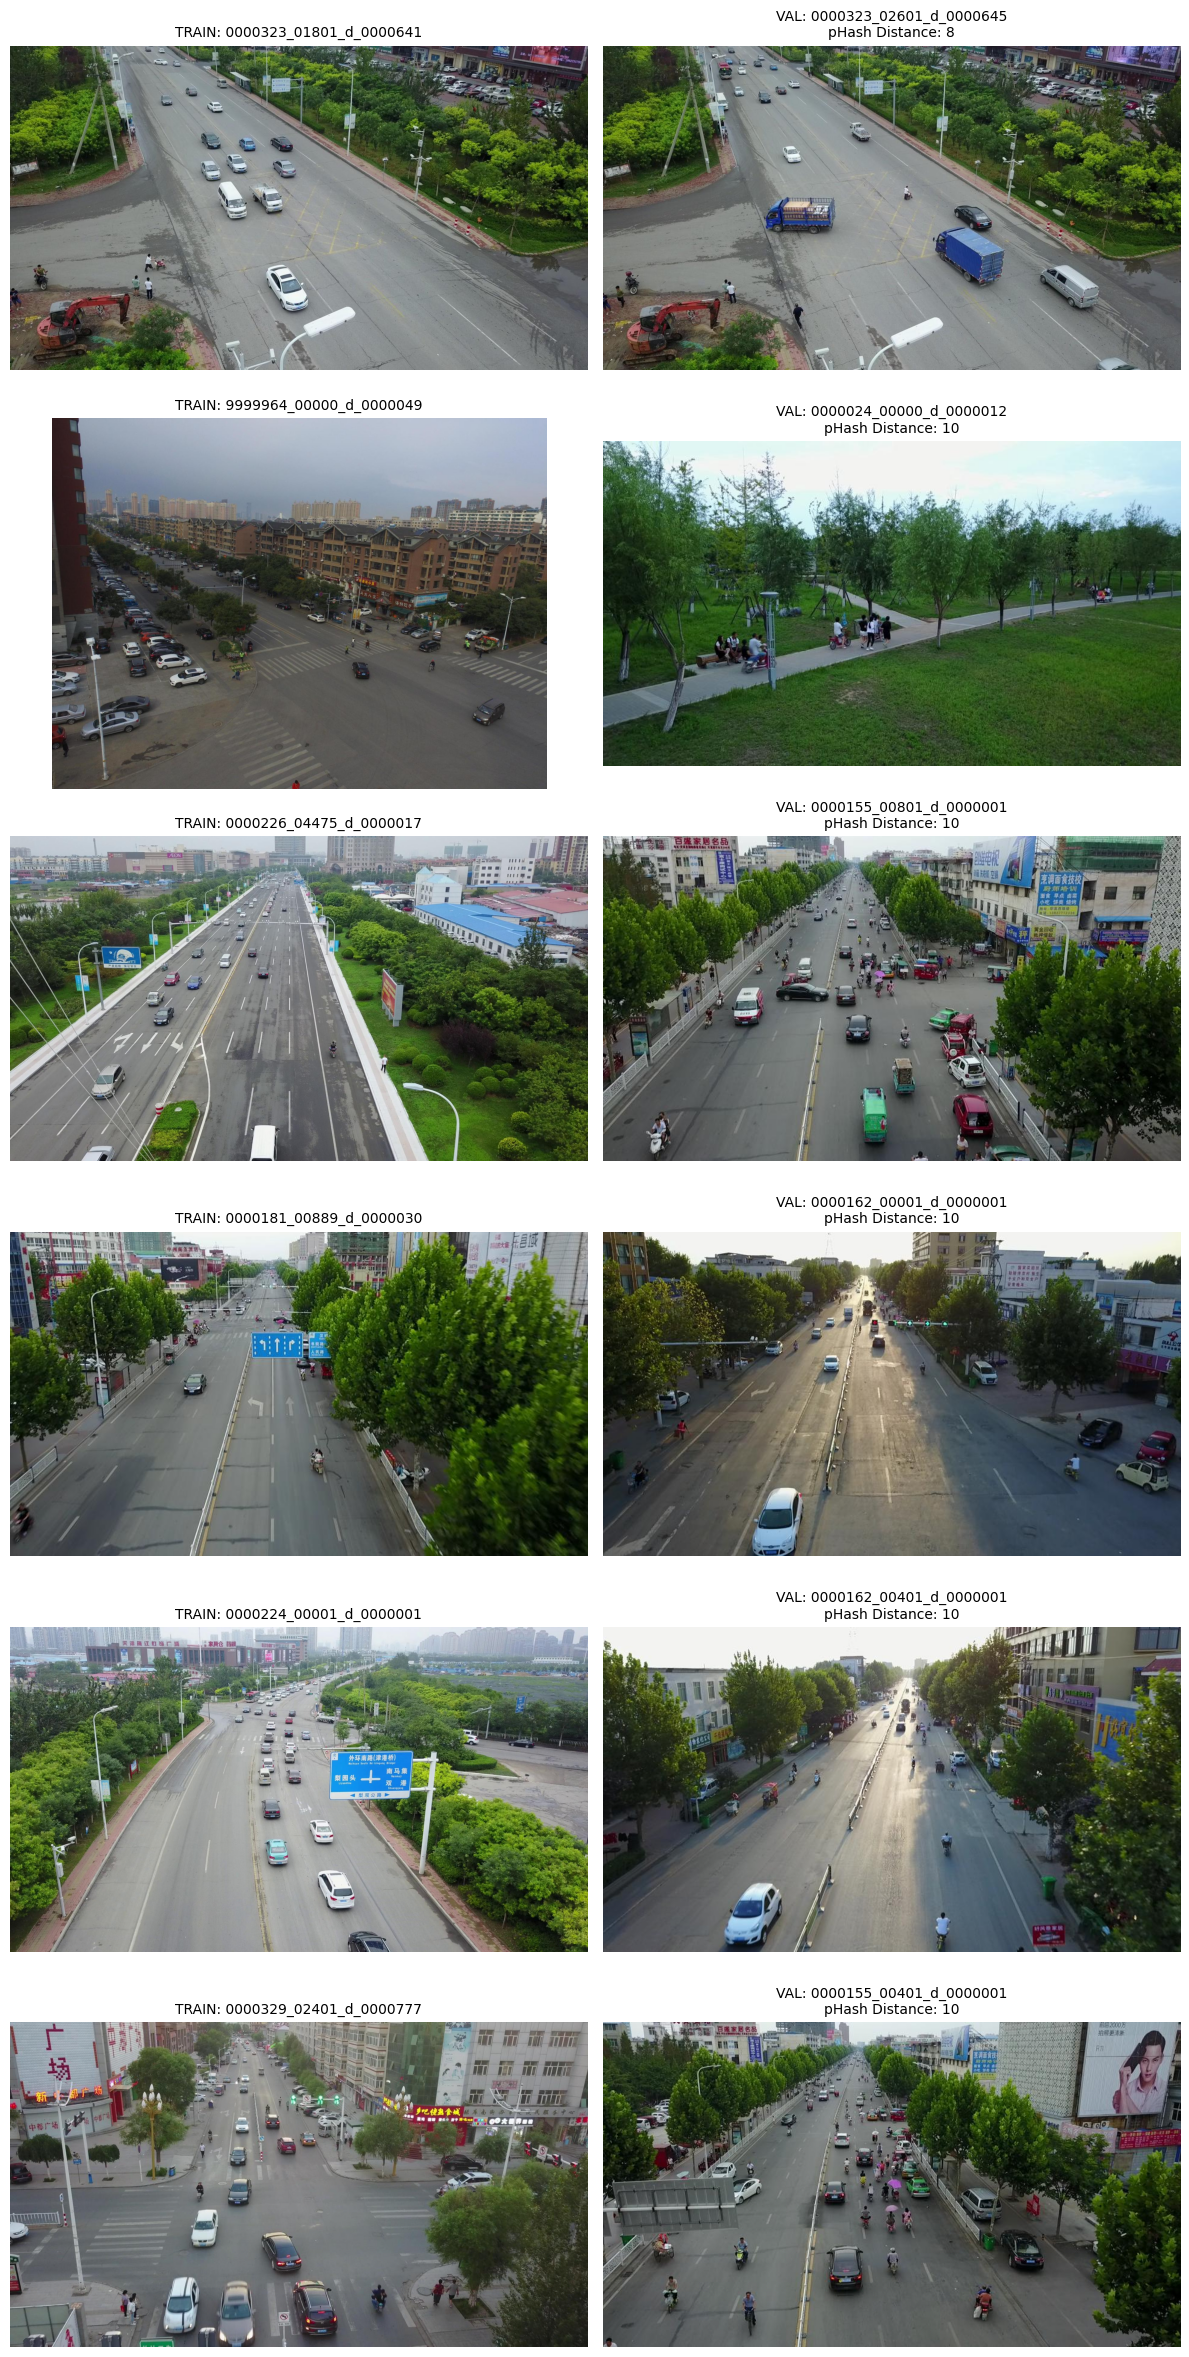

In [124]:
import matplotlib.pyplot as plt
from PIL import Image

top_matches = near_duplicate_df.head(6)

fig, axes = plt.subplots(
    len(top_matches), 2,
    figsize=(12, 4 * len(top_matches))
)

for i, (_, row) in enumerate(top_matches.iterrows()):

    train_path = train_dir / f"{row['train_image']}.jpg"
    val_path = val_dir / f"{row['val_image']}.jpg"

    with Image.open(train_path) as img:
        axes[i, 0].imshow(img.convert("RGB"))

    with Image.open(val_path) as img:
        axes[i, 1].imshow(img.convert("RGB"))

    axes[i, 0].set_title(
        f"TRAIN: {row['train_image']}",
        fontsize=10
    )

    axes[i, 1].set_title(
        f"VAL: {row['val_image']}\n"
        f"pHash Distance: {row['phash_distance']}",
        fontsize=10
    )

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

**Ne gördük?**

- En benzer çift (mesafe 8) **aynı kavşak**. Aynı binalar, aynı kepçe, ama farklı kareler ve farklı araçlar. Yani aynı görüntü değil, aynı videonun farklı anları.
- Diğer çiftlerde (mesafe 10) görüntüler birbirine yalnızca **tarz olarak** benziyor (hepsi uzayıp giden bir cadde manzarası), ama farklı yerler.
- Sonuç: birebir kopya yok, ama bazı validation görüntüleri train'dekiyle aynı sahneden gelebiliyor. Bu ciddi bir sızıntı sayılmaz ama validation sonuçlarını yorumlarken aklımızda tutmalıyız.

## 11. Dışlanan Kayıtların Raporu

Analiz boyunca bazı kayıtları dışarıda bıraktık (ignored regions, geçersiz kutu gibi). Burada **hangi kayıt neden dışarıda kaldı** onu tek tabloda topluyoruz. Her kayıt için tek bir ana neden atanıyor:

| Neden | Anlamı |
|---|---|
| `keep` | Geçerli nesne, analizde ve eğitimde kullanılıyor |
| `excluded_category` | Category 1-10 dışında (ignored regions ve others) |
| `invalid_score` | Gerçek nesne sınıfı ama score = 1 değil |
| `invalid_bbox` | Genişliği ya da yüksekliği 0 olan kutu |

In [125]:
import pandas as pd
from pathlib import Path

def build_exclusion_report(df, split):
    valid_category = df["category"].between(1, 10)
    valid_score = df["score"] == 1
    valid_bbox = (
        (df["bbox_width"] > 0) &
        (df["bbox_height"] > 0)
    )

    # Her kayıt için tek bir ana dışlama nedeni
    reasons = pd.Series("keep", index=df.index)

    reasons.loc[~valid_category] = "excluded_category"
    reasons.loc[valid_category & ~valid_score] = "invalid_score"
    reasons.loc[
        valid_category & valid_score & ~valid_bbox
    ] = "invalid_bbox"

    report = (
        reasons.value_counts()
        .rename_axis("reason")
        .reset_index(name="count")
    )

    report.insert(0, "split", split)

    excluded = df.loc[reasons != "keep"].copy()
    excluded["exclusion_reason"] = reasons.loc[
        reasons != "keep"
    ]

    return report, excluded


train_report, train_excluded = build_exclusion_report(
    train_df, "train"
)

val_report, val_excluded = build_exclusion_report(
    val_df, "validation"
)

exclusion_summary = pd.concat(
    [train_report, val_report],
    ignore_index=True
)

display(exclusion_summary)

print("Train excluded:", len(train_excluded))
print("Validation excluded:", len(val_excluded))

,split,reason,count
0,train,keep,343204
1,train,excluded_category,10345
2,train,invalid_bbox,1
3,validation,keep,38759
4,validation,excluded_category,1410


Train excluded: 10346
Validation excluded: 1410


**Ne gördük?**

- Train'de 343.204 kayıt kullanılıyor, 10.346 kayıt dışarıda kalıyor. Bunun 10.345'i `excluded_category` (ignored regions ve others), sadece 1'i `invalid_bbox`. O 1 kayıt, daha önce bulduğumuz yüksekliği 0 olan `car` kutusu.
- Validation'da 38.759 kayıt kullanılıyor, 1.410 kayıt dışarıda kalıyor ve hepsi `excluded_category`.
- Hiçbir sette `invalid_score` yok, yani 3. bölümdeki score kontrolüyle tutarlı.
- Dışarıda kalan kayıtların neredeyse hepsi hatalı veri değil, veri setinin zaten eğitimde kullanılmayan ignored/others bölgeleri.

### Raporları kaydetme

Dışlama özetini ve dışarıda bırakılan kayıtların kendisini CSV olarak `experiments/eda/logs` klasörüne kaydediyoruz. Böylece sonradan "hangi annotation neden elendi?" sorusuna bakmak ya da deneyi tekrar üretmek kolay olur.

In [126]:
logs_dir = Path.home() / "rtdetr_reproduction" / "RT-DETR" / "experiments" / "eda" / "logs"
logs_dir.mkdir(parents=True, exist_ok=True)

exclusion_summary.to_csv(
    logs_dir / "exclusion_summary.csv",
    index=False
)

train_excluded.to_csv(
    logs_dir / "train_excluded_annotations.csv",
    index=False
)

val_excluded.to_csv(
    logs_dir / "val_excluded_annotations.csv",
    index=False
)

print("Raporlar kaydedildi:", logs_dir)

Raporlar kaydedildi: /Users/iremkeser/rtdetr_reproduction/RT-DETR/experiments/eda/logs


Üç dosya kaydedildi: `exclusion_summary.csv` (özet tablo), `train_excluded_annotations.csv` ve `val_excluded_annotations.csv` (dışarıda kalan kayıtlar, her birinde `exclusion_reason` sütunu ile).